# Stage 4 v2 ? Intrinsic Karst Vulnerability (Mole Creek prototype)

Combines Stage 2 karst intensity and exposure with Stage 7.1 log-scale D8 hydrological connectivity into **intrinsic karst vulnerability**. This answers: *if something happens on the surface, where is the underlying karst system relatively more vulnerable?*

**Combination method:** multiply the three normalized inputs: `intensity_norm * exposure_norm * connectivity_D8_norm`. The Stage 2 scales are normalized by their maxima (intensity 0?4, exposure 0?3); the Stage 7.1 log-scale D8 connectivity classes (1?4) are normalized by 4. The DEM valid-data mask determines which cells are included.


In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import rasterio
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..") / "src"))
from karst import classify_scores
from mapping import add_attribution, add_basemap, data_bounds, finish_map, plot_scores, scores_legend

data = Path(os.environ.get("AT3_DATA_DIR", "data"))
outpath = data / "Output_data"

with rasterio.open(outpath / "karst_intensity_mc_EPSG7855.tif") as src:
    intensity = src.read(1).astype(float)
    profile = src.profile
with rasterio.open(outpath / "karst_exposure_mc_EPSG7855.tif") as src:
    exposure = src.read(1).astype(float)
with rasterio.open(outpath / "connectivity_logscale4_mc_25m_EPSG7855_alt3.tif") as src:
    connectivity_d8 = src.read(1).astype(float)
with rasterio.open(outpath / "dem_mc_EPSG7855.tif") as src:
    dem = src.read(1)
    dem_nodata = src.nodata

valid = dem != dem_nodata


## 4.1 Normalise and combine

Normalize the Stage 2 intensity (0?4), Stage 2 exposure (0?3), and Stage 7.1 log-scale D8 connectivity (1?4) to 0?1, then multiply them cell by cell.


In [15]:
intensity_norm = intensity / 4.0          # max KCATEGORY score from Stage 2
exposure_norm = exposure / 3.0            # max exposure score from Stage 2
connectivity_D8_norm = connectivity_d8 / 4.0  # max log-scale D8 class from Stage 7.1

intrinsic = intensity_norm * exposure_norm * connectivity_D8_norm
intrinsic[~valid] = np.nan

print("Distinct combined score values present:", np.unique(intrinsic[valid]))


Distinct combined score values present: [0.         0.0625     0.08333333 0.125      0.16666667 0.1875
 0.25       0.33333333 0.375      0.5        0.66666667 0.75      ]


## 4.2 Classify

Classified directly on whatever distinct combined values occur (via `classify_scores()` in `src/karst.py`). A handful of discrete ordinal inputs produces only a few real combinations, so exact-value classes are more meaningful than quantile breaks. Labels are generated from the values present, so a change to the upstream scoring flows through without edits here.

Class distribution (valid cells):
  Class 0 (0.000) (score=0.0000): 1435887 cells (77.7%)
  Class 1 (0.062) (score=0.0625): 28511 cells (1.5%)
  Class 2 (0.083) (score=0.0833): 6270 cells (0.3%)
  Class 3 (0.125) (score=0.1250): 24111 cells (1.3%)
  Class 4 (0.167) (score=0.1667): 132825 cells (7.2%)
  Class 5 (0.188) (score=0.1875): 2554 cells (0.1%)
  Class 6 (0.250) (score=0.2500): 172332 cells (9.3%)
  Class 7 (0.333) (score=0.3333): 17729 cells (1.0%)
  Class 8 (0.375) (score=0.3750): 438 cells (0.0%)
  Class 9 (0.500) (score=0.5000): 27379 cells (1.5%)
  Class 10 (0.667) (score=0.6667): 51 cells (0.0%)
  Class 11 (0.750) (score=0.7500): 323 cells (0.0%)


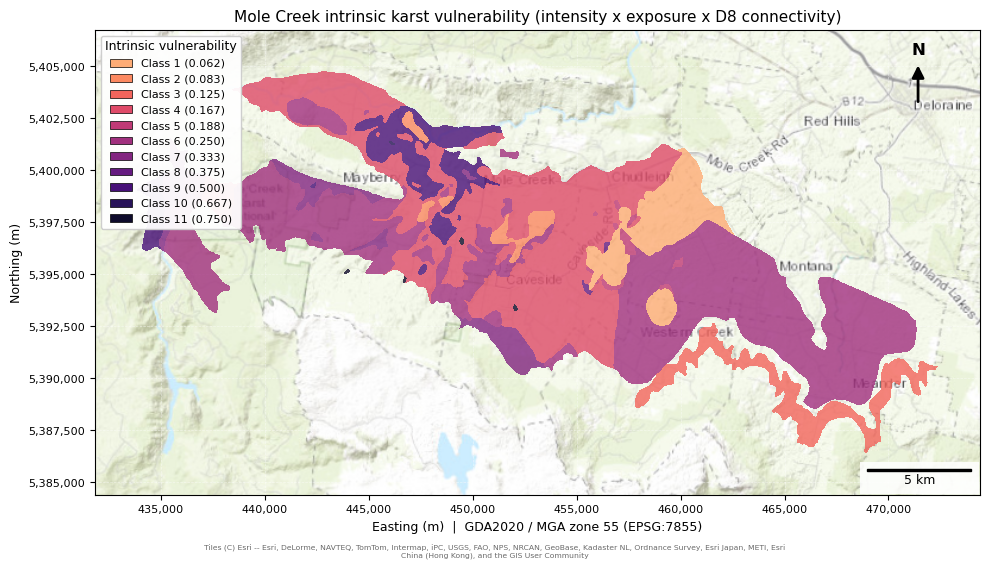

In [16]:
intrinsic_class, present, LABELS = classify_scores(intrinsic, valid)

print("Class distribution (valid cells):")
for i, (val, label) in enumerate(zip(present, LABELS)):
    n = (intrinsic_class == i).sum()
    print(f"  {label} (score={val:.4f}): {n} cells ({n/valid.sum()*100:.1f}%)")

out_profile = profile.copy()
out_profile.update(dtype="uint8", nodata=255)
with rasterio.open(outpath / "intrinsic_vulnerability_v2_mc_EPSG7855.tif", "w", **out_profile) as dst:
    dst.write(intrinsic_class, 1)

# Also save the continuous (unclassified) score -- Stage 6 needs the real
# relative spacing, not the class index, which would distort it
intrinsic_raw = np.where(valid, intrinsic, -9999).astype("float32")
raw_profile = profile.copy()
raw_profile.update(dtype="float32", nodata=-9999)
with rasterio.open(outpath / "intrinsic_vulnerability_v2_raw_mc_EPSG7855.tif", "w", **raw_profile) as dst:
    dst.write(intrinsic_raw, 1)

bounds = data_bounds(valid & (intrinsic > 0), profile["transform"])
fig, ax = plt.subplots(figsize=(10, 5.6))
add_basemap(ax, bounds, zoom=11)
plot_scores(ax, intrinsic_class, profile["transform"], len(present))
scores_legend(ax, LABELS, title="Intrinsic vulnerability")
ax.set_title("Mole Creek intrinsic karst vulnerability (intensity x exposure x D8 connectivity)", fontsize=11)
finish_map(ax)
add_attribution(ax)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


## Three-factor intrinsic vulnerability

This version combines intensity, exposure, and log-scale D8 connectivity. Exposure and connectivity both affect the result, so a high intensity score alone does not produce a high intrinsic vulnerability score where either exposure or connectivity is low. Connectivity is scored from the Stage 7.1 four-class log-scale classification in `03alt3_hydrological_connectivity`.


## Stage 4 v2 outputs

- `intrinsic_vulnerability_v2_mc_EPSG7855.tif` ? classified three-factor intrinsic vulnerability (class labels are generated from values present)
- `intrinsic_vulnerability_v2_raw_mc_EPSG7855.tif` ? continuous, unclassified three-factor score for downstream use

**Next (Stage 5):** land-use pressure from DEA Level-3 land cover, the first layer that should vary outside the karst polygons themselves, now that the Mole Creek boundary includes surrounding land (see the buffer in Stage 0).


## 4.3 Compare five-class intrinsic vulnerability maps

Display two maps of the positive intrinsic vulnerability scores: one classified with five equal-interval classes and one with five Natural Jenks classes. Zero scores and DEM NoData cells are excluded from both maps. The legend labels are Very Low, Low, Moderate, High, and Very High. These comparison maps are displayed only and are not saved.


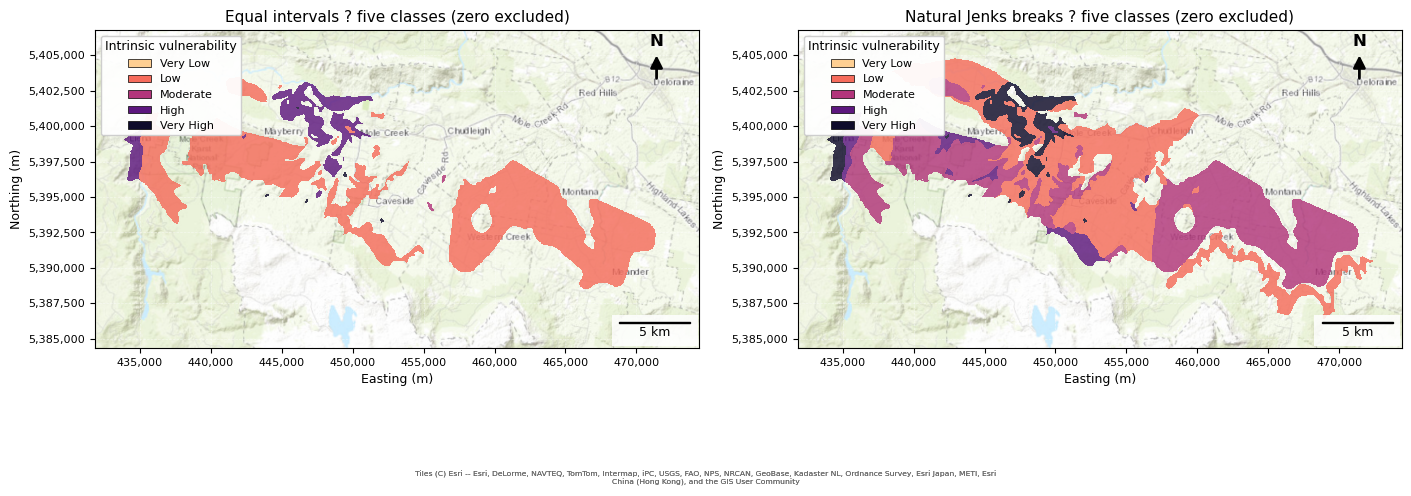

In [14]:
# Compare five positive-score classes using equal intervals and weighted Natural Jenks.
from matplotlib.colors import ListedColormap

positive_valid = valid & np.isfinite(intrinsic) & (intrinsic > 0)
if not positive_valid.any():
    raise ValueError("No positive intrinsic vulnerability scores are available to map")

# classify_scores supplies the ordered distinct score values and their canonical labels.
exact_score_class, score_values, LABELS = classify_scores(intrinsic, positive_valid)
score_values = np.asarray(score_values, dtype="float64")
score_counts = np.array([(exact_score_class == i).sum() for i in range(len(score_values))], dtype="float64")
if len(score_values) < 5:
    raise ValueError(f"Five positive-score classes require at least five distinct scores; found {len(score_values)}")

# Weighted within-class sum of squares for every contiguous interval of distinct scores.
prefix_w = np.concatenate(([0.0], np.cumsum(score_counts)))
prefix_x = np.concatenate(([0.0], np.cumsum(score_values * score_counts)))
prefix_x2 = np.concatenate(([0.0], np.cumsum(score_values * score_values * score_counts)))
def _jenks_cost(start, stop):
    weight = prefix_w[stop] - prefix_w[start]
    total = prefix_x[stop] - prefix_x[start]
    squares = prefix_x2[stop] - prefix_x2[start]
    return max(0.0, squares - total * total / weight)

def _weighted_jenks_groups(class_count):
    value_count = len(score_values)
    costs = np.full((class_count + 1, value_count + 1), np.inf)
    previous = np.full((class_count + 1, value_count + 1), -1, dtype=int)
    costs[0, 0] = 0.0
    for classes in range(1, class_count + 1):
        for stop in range(classes, value_count + 1):
            for start in range(classes - 1, stop):
                candidate = costs[classes - 1, start] + _jenks_cost(start, stop)
                if candidate < costs[classes, stop]:
                    costs[classes, stop] = candidate
                    previous[classes, stop] = start
    groups = []
    stop = value_count
    for classes in range(class_count, 0, -1):
        start = previous[classes, stop]
        groups.append((start, stop))
        stop = start
    return list(reversed(groups))

class_count = 5
class_labels = ["Very Low", "Low", "Moderate", "High", "Very High"]
equal_edges = np.linspace(score_values.min(), score_values.max(), class_count + 1)
jenks_groups = _weighted_jenks_groups(class_count)
jenks_thresholds = np.array([
    (score_values[jenks_groups[i][1] - 1] + score_values[jenks_groups[i + 1][0]]) / 2
    for i in range(class_count - 1)
])

map_specs = [
    ("Equal intervals", equal_edges[1:-1]),
    ("Natural Jenks breaks", jenks_thresholds),
]
map_bounds = data_bounds(positive_valid, profile["transform"])
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, (method_name, thresholds) in zip(axes, map_specs):
    class_raster = np.full(intrinsic.shape, 255, dtype="uint8")
    class_raster[positive_valid] = np.digitize(
        intrinsic[positive_valid], thresholds, right=True
    ).astype("uint8")
    add_basemap(ax, map_bounds, zoom=11)
    plot_scores(ax, class_raster, profile["transform"], class_count, alpha=0.82)
    scores_legend(ax, class_labels, title="Intrinsic vulnerability", skip=())
    ax.set_title(f"{method_name} ? five classes (zero excluded)", fontsize=11)
    finish_map(ax)
    ax.set_xlabel("Easting (m)", fontsize=9)
    ax.set_ylabel("Northing (m)", fontsize=9)
    add_attribution(ax)
plt.show()
